In [1]:
root = "M://Diploma/experiments/vesuvius/fragments"

### Data loading

For the baseline, we will do simple per-pixel classification. That is, we do not account for the neighborhood in any way. The only input we use are the raw pixel values from IR/CT.

Since fitting all 65 CT layers into RAM is infeasible (takes up more than 100 GB), here we will also select the most useful of those for further experiments, so that we do not have to worry about implementing models in external memory.

In [2]:
import numpy
import typing
import PIL.Image

def load_fragment(fragment: int, depths: typing.Optional[typing.List[int]]):
    mask = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/mask.png")) > 0
    pixels = numpy.flatnonzero(mask)
    ink = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/inklabels.png")).ravel()[pixels] > 0

    if depths is None:
        ir = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/ir.png")).ravel()[pixels]
        return numpy.expand_dims(ir, 1), ink

    ct = numpy.empty((len(pixels), len(depths)), dtype=numpy.float32)
    for i, depth in enumerate(depths):
        ct[:, i] = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/surface_volume/{depth:02d}.tif")).ravel()[pixels]
    return ct, ink

def load_fragments(fragments, depths: typing.Optional[typing.List[int]]):
    values = list(load_fragment(fragments[0], depths))
    for fragment in fragments[1:]:
        fragment_values = load_fragment(fragment, depths)
        for i in range(len(values)):
            values[i] = numpy.concatenate([ values[i], fragment_values[i] ])
    return values

### Evaluation metrics

The main metric used in the competition is the $F_{0.5}$ score defined as follows:
$$ F_{0.5} = \dfrac{1.25 pr}{0.25 p + r} = \dfrac{1.25 TP}{1.25TP + FP + 0.25FN} $$
This metric scores precision higher than recall, which is designed to improve the ability to form coherent characters out of detected ink areas.

Additionally, for a more comprehensive evaluation, we compute the other typical segmentation metrics: per-pixel accuracy, precison, recall, F1-score, ROC-AUC, and Jaccard score.

For the leaderboard, the competition uses additional private data, which is not available in this project. To circumvent this, we will use Fragment 4 as a held-out test object used for evaluation. The results should generally reflect the scores in the competition, although direct comparison to the metrics reported there is not possible.

In [3]:
import numpy
import sklearn.metrics
import matplotlib.pyplot as plt

def estimate_quality(pred_proba: numpy.ndarray, masks: numpy.ndarray) -> dict:
    scores = pred_proba.flatten()
    preds = (scores >= 0.5).astype(numpy.int8)
    targets = masks.flatten().astype(numpy.int8)
    return {
        "F0.5": sklearn.metrics.fbeta_score(targets, preds, beta=0.5, zero_division=0),
        "Accuracy": sklearn.metrics.accuracy_score(targets, preds),
        "AUC-ROC": sklearn.metrics.roc_auc_score(targets, scores),
        "Precision": sklearn.metrics.precision_score(targets, preds, zero_division=0),
        "Recall": sklearn.metrics.recall_score(targets, preds, zero_division=0),
        "F1-score": sklearn.metrics.f1_score(targets, preds, zero_division=0),
        "Jaccard score": sklearn.metrics.jaccard_score(targets, preds, zero_division=0),
    }

def plot_prediction(pred_proba: numpy.ndarray, fragment: int):
    mask = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/mask.png")) > 0
    target = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/inklabels.png")) > 0
    prediction = numpy.zeros(mask.shape, dtype=bool)
    prediction[mask] = pred_proba.ravel() >= 0.5

    fig, axes = plt.subplots(1, 2, figsize=(5, 4))
    axes[0].imshow(target, cmap="gray", vmin=0, vmax=1)
    axes[0].set_title("Ink target")
    axes[1].imshow(prediction, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Predicted ink")
    for ax in axes:
        ax.axis("off")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

In all the following experiments, we explore two predictions: one formed from the infrared scans, and one from the 65 layers of the CT scans. The final evaluation matching the competition is only the latter one, yet the easier IR task is a simpler one that might give us some insight into the dataset and help devise a model for the harder part.

For this notebook, we also perform multiple CT experiments with different subsets of layers to find the ones that have no useful information and can be discarded from further experiments for performance reasons.

In [4]:
import sklearn.base

def try_ir(model: sklearn.base.ClassifierMixin):
    train_X, train_y = load_fragments([1, 2, 3], depths=None)
    test_X, test_y = load_fragments([4], depths=None)

    model = model.fit(train_X, train_y)
    preds = model.predict_proba(test_X)[:, 1]
    print(estimate_quality(preds, test_y))
    plot_prediction(preds, fragment=4)

### Dummy classifiers

First, let's try the simplest models that just predict constants.

In [5]:
import sklearn.dummy

d:\Programs\Programming\Python\lib\site-packages\PIL\Image.py:3402: DecompressionBombWarning: Image size (140973980 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


{'F0.5': 0.0, 'Accuracy': 0.8961759286018581, 'AUC-ROC': 0.5, 'Precision': 0.0, 'Recall': 0.0, 'F1-score': 0.0, 'Jaccard score': 0.0}


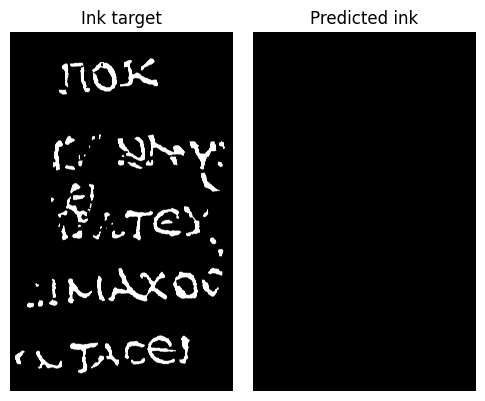

In [6]:
try_ir(sklearn.dummy.DummyClassifier(strategy="constant", constant=0))

d:\Programs\Programming\Python\lib\site-packages\PIL\Image.py:3402: DecompressionBombWarning: Image size (140973980 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


{'F0.5': 0.12649673766688765, 'Accuracy': 0.10382407139814193, 'AUC-ROC': 0.5, 'Precision': 0.10382407139814193, 'Recall': 1.0, 'F1-score': 0.1881170633770194, 'Jaccard score': 0.10382407139814193}


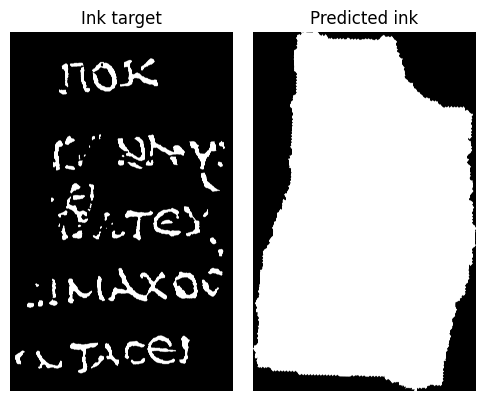

In [7]:
try_ir(sklearn.dummy.DummyClassifier(strategy="constant", constant=1))

Expectdly, the $F_{0.5}$ score is zero. However, the class imbalance here is obvious: only 10% of pixels are labeled as having inc.